# Part 2 Exploratory Data Analysis

This notebook performs a comprehensive analysis of the 10 time series datasets from Part 2 to determine suitable trading strategies.

## Analysis Objectives
Classify 10 assets into 3 strategy types:
1. **Trend/Momentum Strategy** - Suitable for assets with clear directional trends
2. **Mean Reversion Strategy** - Suitable for assets where prices oscillate around the mean and returns exhibit reversal characteristics
3. **Breakout Strategy** - Suitable for assets with distinct support/resistance levels and price continuation after breakouts

## Analysis Methods
1. Basic statistical analysis
2. Price chart visualization
3. Correlation analysis
4. Hurst Exponent - Determine trending (H>0.5) vs. mean-reverting (H<0.5)
5. Return autocorrelation analysis - Momentum/reversal effects
6. Breakout effectiveness analysis
7. Mean reversion characteristics testing
8. ADX trend strength analysis
9. Composite scoring and strategy classification

## NOTE
- This notebook currently runs on the Part 2 dataset by default. To generate the corresponding analysis for Part 3 dataset, simply change DATA_PATH in the first cell from PART2 to PART3 and rerun the notebook from top to bottom.

Please creat a cell and run the following command to install the required packages for data analysis: %pip install pandas numpy matplotlib seaborn scipy statsmodels

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats
from statsmodels.tsa.stattools import adfuller, acf
import warnings
warnings.filterwarnings('ignore')

# Set plot style - inline display in Jupyter
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 10

# Data paths
DATA_PATH = Path("./DATA/PART2")
FIGURES_PATH = Path('./figures')
FIGURES_PATH.mkdir(exist_ok=True)

print(f'Data path: {DATA_PATH.absolute()}')
print(f'Figures save path: {FIGURES_PATH.absolute()}')

Data path: c:\Users\14671\Desktop\Strategy_Research_and_Development\DATA\PART2
Figures save path: c:\Users\14671\Desktop\Strategy_Research_and_Development\figures


## 1. Data Loading

In [2]:
# Load all 10 CSV files
data = {}
for i in range(1, 11):
    filename = f'{i:02d}.csv'
    filepath = DATA_PATH / filename
    df = pd.read_csv(filepath)
    
    # Check date column name
    date_col = 'Index' if 'Index' in df.columns else 'Date'
    df[date_col] = pd.to_datetime(df[date_col])
    df.set_index(date_col, inplace=True)
    df.sort_index(inplace=True)
    
    data[f'series_{i}'] = df
    print(f'Series {i}: {len(df)} rows, {df.index.min().date()} to {df.index.max().date()}')

print(f'\nLoaded {len(data)} series in total')

Series 1: 1000 rows, 2072-09-03 to 2075-05-30
Series 2: 1000 rows, 2072-09-03 to 2075-05-30
Series 3: 1000 rows, 2072-09-03 to 2075-05-30
Series 4: 1000 rows, 2072-09-03 to 2075-05-30
Series 5: 1000 rows, 2072-09-03 to 2075-05-30
Series 6: 1000 rows, 2072-09-03 to 2075-05-30
Series 7: 1000 rows, 2072-09-03 to 2075-05-30
Series 8: 1000 rows, 2072-09-03 to 2075-05-30
Series 9: 1000 rows, 2072-09-03 to 2075-05-30
Series 10: 1000 rows, 2072-09-03 to 2075-05-30

Loaded 10 series in total


In [3]:
# View the data structure of the first series
print('Data columns:', data['series_1'].columns.tolist())
print('\nData sample:')
data['series_1'].head()

Data columns: ['Open', 'High', 'Low', 'Close', 'Volume']

Data sample:


,Open,High,Low,Close,Volume
Index,,,,,
2072-09-03,14.60,14.87,14.60,14.81,7228
2072-09-04,14.94,15.34,14.94,15.15,17353
2072-09-05,15.11,15.25,15.00,15.11,6024
2072-09-06,15.11,15.30,15.08,15.14,7173
2072-09-07,15.24,15.24,15.09,15.20,6136


## 2. Basic Statistics

In [4]:
# Collect basic statistics of Close prices for all series
stats_list = []

for name, df in data.items():
    close = df['Close']
    returns = close.pct_change().dropna()
    
    # Use series_stat to avoid conflict with scipy.stats
    series_stat = {
        'Series': name,
        'Start Date': df.index.min().date(),
        'End Date': df.index.max().date(),
        'Days': len(df),
        'Start Price': close.iloc[0],
        'End Price': close.iloc[-1],
        'Min Price': close.min(),
        'Max Price': close.max(),
        'Mean Price': close.mean(),
        'Std Price': close.std(),
        'Total Return (%)': (close.iloc[-1] / close.iloc[0] - 1) * 100,
        'Daily Return Mean (%)': returns.mean() * 100,
        'Daily Return Std (%)': returns.std() * 100,
        'Sharpe (approx)': returns.mean() / returns.std() * np.sqrt(252) if returns.std() > 0 else 0,
        'Max Drawdown (%)': ((close / close.cummax()) - 1).min() * 100,
        'Skewness': returns.skew(),
        'Kurtosis': returns.kurtosis()
    }
    stats_list.append(series_stat)

stats_df = pd.DataFrame(stats_list)
stats_df.set_index('Series', inplace=True)

print('=== Basic Statistics for All Series ===')
stats_df.round(4)

=== Basic Statistics for All Series ===


,Start Date,End Date,Days,Start Price,End Price,Min Price,Max Price,Mean Price,Std Price,Total Return (%),Daily Return Mean (%),Daily Return Std (%),Sharpe (approx),Max Drawdown (%),Skewness,Kurtosis
Series,,,,,,,,,,,,,,,,
series_1,2072-09-03,2075-05-30,1000,14.8100,25.0400,14.4100,34.8500,20.6267,4.5313,69.0749,0.0698,1.8962,0.5841,-45.8824,4.1017,61.0637
series_2,2072-09-03,2075-05-30,1000,206.0000,235.5000,189.2500,330.5000,228.2195,28.2766,14.3204,0.0280,1.7311,0.2565,-41.0741,2.6031,29.8469
series_3,2072-09-03,2075-05-30,1000,0.6573,0.8319,0.6203,0.8480,0.7050,0.0691,26.5632,0.0248,0.4933,0.7981,-7.4455,-0.1695,1.3494
series_4,2072-09-03,2075-05-30,1000,33.1200,60.6200,17.9700,61.2800,34.0901,10.1519,83.0314,0.0992,2.7661,0.5691,-49.3089,-0.2209,17.0059
series_5,2072-09-03,2075-05-30,1000,115.5000,88.2800,80.6000,121.2100,100.8501,12.4834,-23.5671,-0.0253,0.5660,-0.7096,-33.5038,0.0935,2.1853
series_6,2072-09-03,2075-05-30,1000,4.7980,7.0850,4.0280,8.2200,5.3751,1.1462,47.6657,0.0547,1.8007,0.4818,-32.8102,3.6996,69.6540
series_7,2072-09-03,2075-05-30,1000,100.1562,103.5234,99.9766,108.5156,105.2531,1.9163,3.3620,0.0034,0.1570,0.3471,-4.8668,-1.9197,19.5970
series_8,2072-09-03,2075-05-30,1000,100.8438,111.8438,100.0625,119.7031,110.1092,4.0979,10.9079,0.0115,0.4851,0.3778,-10.1553,-1.2778,7.2757
series_9,2072-09-03,2075-05-30,1000,99.9375,116.5625,98.0312,121.4062,108.4563,5.3058,16.6354,0.0179,0.7090,0.4014,-14.6460,-1.0196,5.4997


In [5]:
# Save statistics
stats_df.to_csv(FIGURES_PATH / 'basic_statistics.csv')
print('Statistics saved to figures/basic_statistics.csv')

Statistics saved to figures/basic_statistics.csv


## 3. Price Chart Visualization

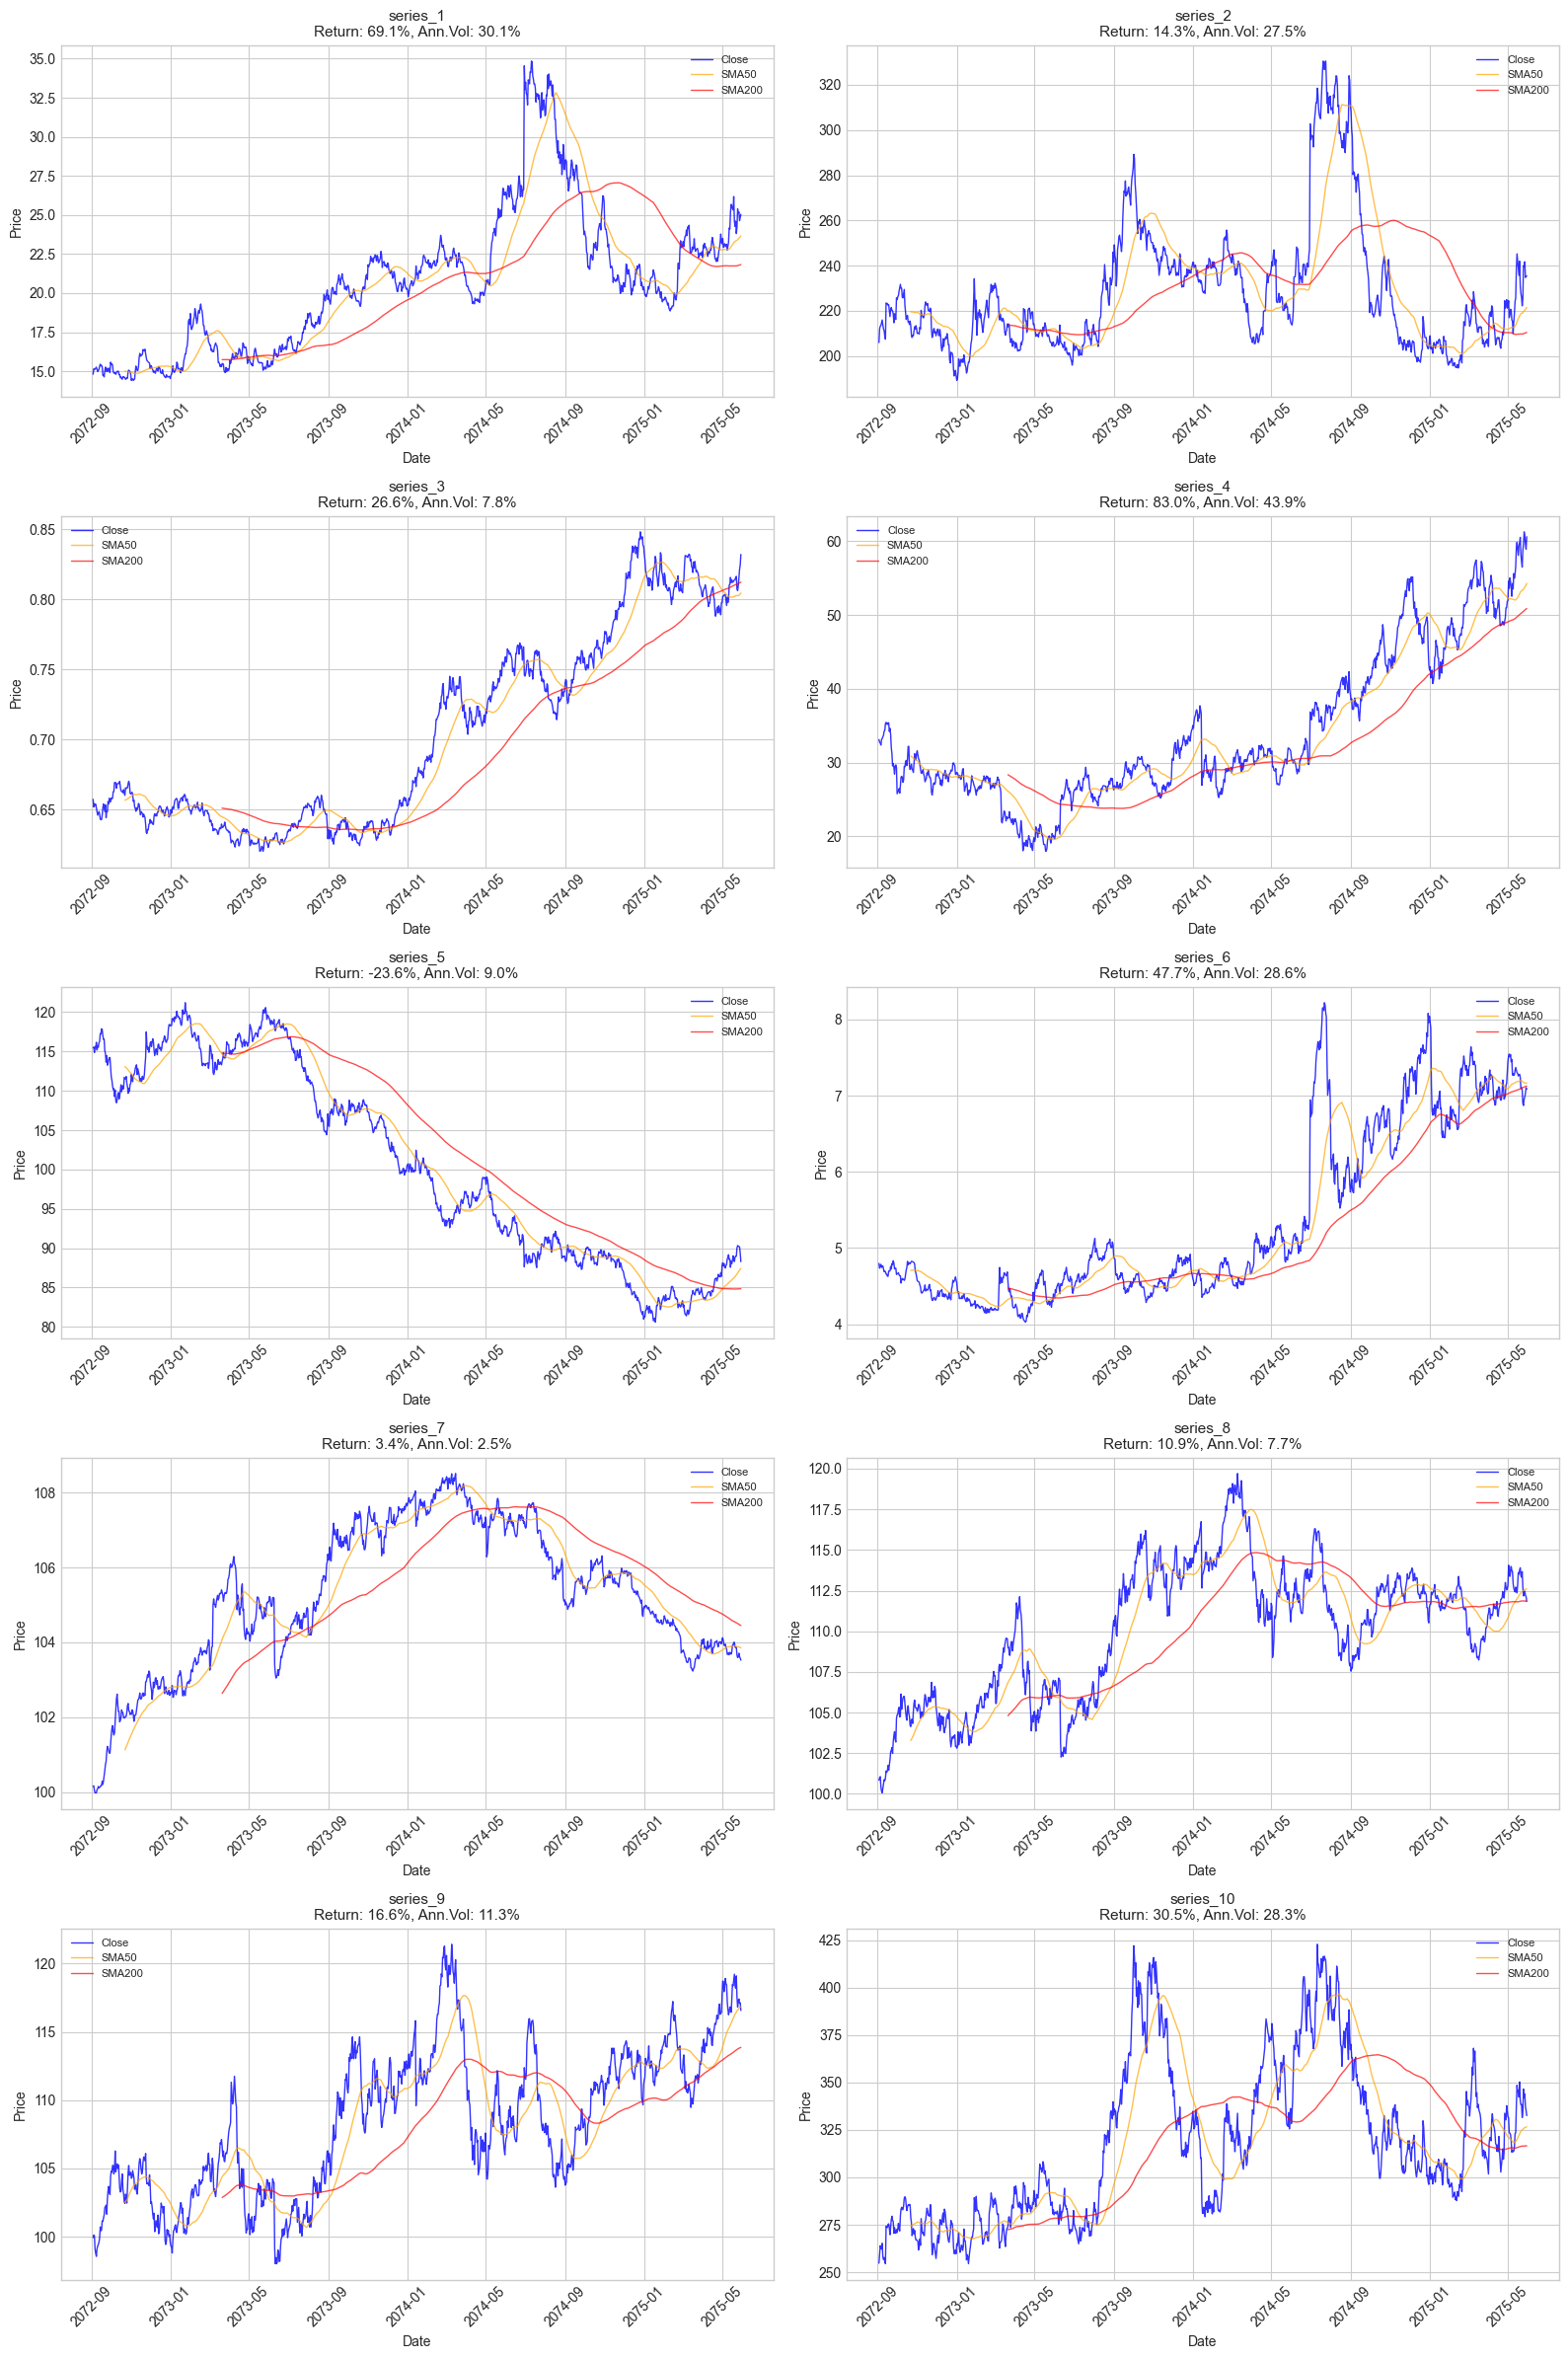

Chart saved to figures/all_series_prices.png


In [6]:
# Plot raw prices for all series (with moving averages)
fig, axes = plt.subplots(5, 2, figsize=(16, 24))
axes = axes.flatten()

for idx, (name, df) in enumerate(data.items()):
    ax = axes[idx]
    close = df['Close']
    
    # Plot price
    ax.plot(df.index, close, linewidth=1, color='blue', alpha=0.8, label='Close')
    
    # Add moving averages to help identify trends
    sma50 = close.rolling(50).mean()
    sma200 = close.rolling(200).mean()
    ax.plot(df.index, sma50, linewidth=1, color='orange', alpha=0.7, label='SMA50')
    ax.plot(df.index, sma200, linewidth=1, color='red', alpha=0.7, label='SMA200')
    
    # Calculate basic statistics
    total_return = (close.iloc[-1] / close.iloc[0] - 1) * 100
    volatility = close.pct_change().std() * np.sqrt(252) * 100
    
    ax.set_title(f'{name}\nReturn: {total_return:.1f}%, Ann.Vol: {volatility:.1f}%', fontsize=11)
    ax.set_xlabel('Date')
    ax.set_ylabel('Price')
    ax.legend(loc='best', fontsize=8)
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(FIGURES_PATH / 'all_series_prices.png', dpi=150, bbox_inches='tight')
plt.show()  # Display chart in notebook
print('Chart saved to figures/all_series_prices.png')

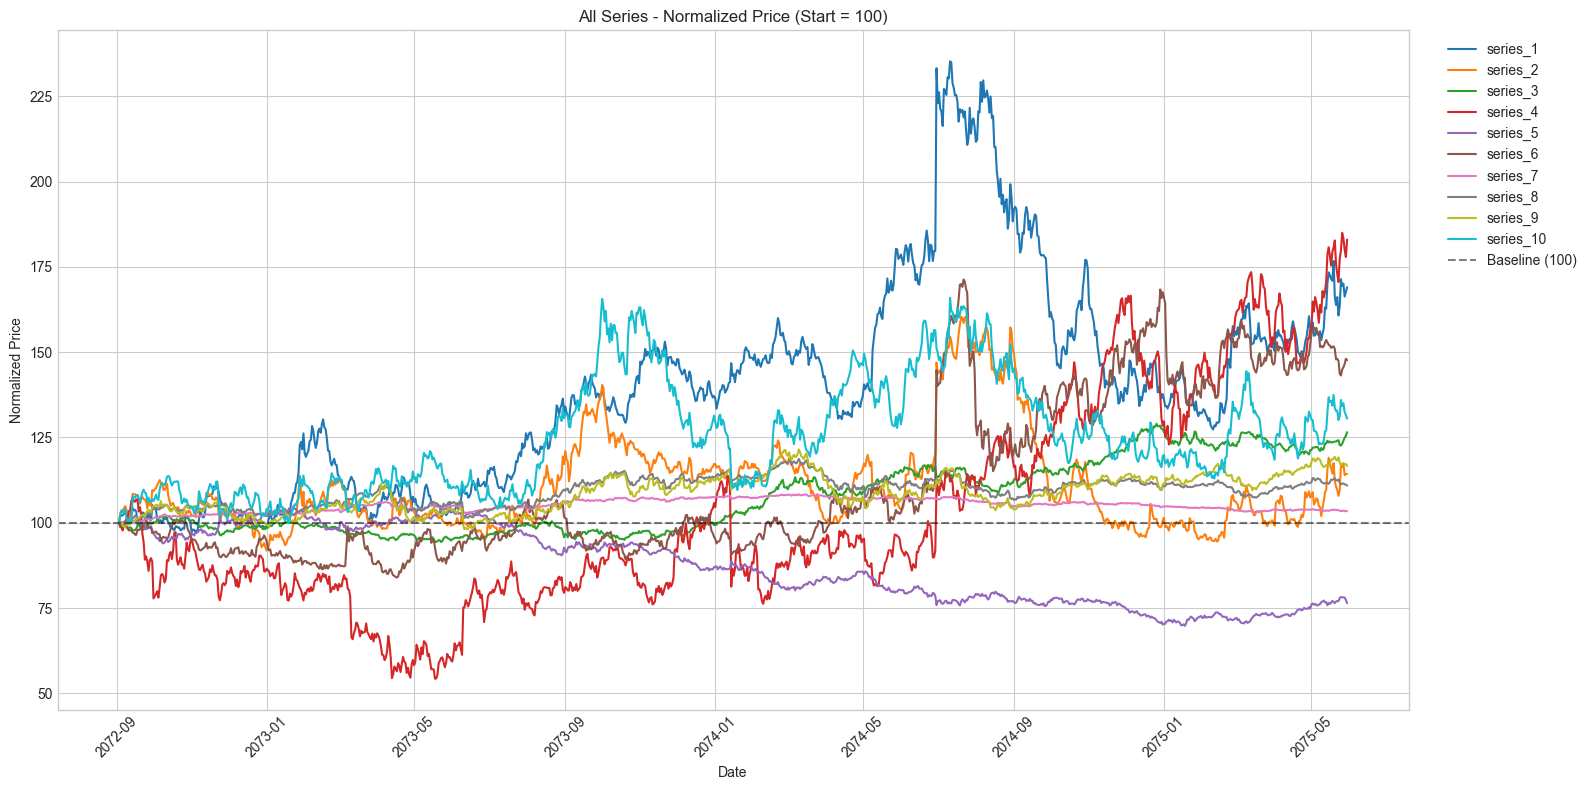

Chart saved to figures/normalized_prices.png


In [7]:
# Normalized price comparison (all series starting at 100)
fig, ax = plt.subplots(figsize=(16, 8))

for name, df in data.items():
    normalized = df['Close'] / df['Close'].iloc[0] * 100
    ax.plot(df.index, normalized, label=name, linewidth=1.5)

ax.axhline(y=100, color='black', linestyle='--', alpha=0.5, label='Baseline (100)')
ax.set_title('All Series - Normalized Price (Start = 100)')
ax.set_xlabel('Date')
ax.set_ylabel('Normalized Price')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(FIGURES_PATH / 'normalized_prices.png', dpi=150, bbox_inches='tight')
plt.show()  # Display chart in notebook
print('Chart saved to figures/normalized_prices.png')

## 4. Returns Analysis

In [8]:
# Calculate daily returns
returns_df = pd.DataFrame()

for name, df in data.items():
    returns_df[name] = df['Close'].pct_change()

returns_df.dropna(inplace=True)
print(f'Returns data: {len(returns_df)} days')
returns_df.head()

Returns data: 999 days


,series_1,series_2,series_3,series_4,series_5,series_6,series_7,series_8,series_9,series_10
Index,,,,,,,,,,
2072-09-04,0.022957,0.029126,-0.008215,-0.011171,0.000433,-0.013130,0.000079,0.001549,0.001876,0.019627
2072-09-05,-0.002640,0.005896,0.003528,-0.003053,-0.005885,0.006336,-0.001248,0.000619,-0.000624,0.016362
2072-09-06,0.001985,0.001172,-0.001681,-0.008576,0.006529,0.004197,-0.000625,-0.006184,-0.009681,-0.004735
2072-09-07,0.003963,0.005855,0.001072,0.022552,-0.001384,-0.008359,0.000000,-0.002801,-0.003155,-0.001903
2072-09-08,0.003947,0.005821,-0.003824,0.004532,0.006236,0.003793,0.000000,-0.000936,-0.002214,0.011439


In [9]:
# Returns distribution
fig, axes = plt.subplots(5, 2, figsize=(16, 20))
axes = axes.flatten()

for idx, col in enumerate(returns_df.columns):
    ax = axes[idx]
    returns_df[col].hist(bins=50, ax=ax, alpha=0.7, edgecolor='black')
    ax.axvline(x=0, color='red', linestyle='--', alpha=0.7)
    ax.axvline(x=returns_df[col].mean(), color='green', linestyle='-', alpha=0.7, label=f'Mean: {returns_df[col].mean()*100:.3f}%')
    ax.set_title(f'{col} - Daily Returns Distribution')
    ax.set_xlabel('Daily Return')
    ax.set_ylabel('Frequency')
    ax.legend()

plt.tight_layout()
plt.savefig(FIGURES_PATH / 'returns_distribution.png', dpi=150, bbox_inches='tight')
plt.close()
print('Chart saved to figures/returns_distribution.png')

Chart saved to figures/returns_distribution.png


## 5. Correlation Analysis

In [10]:
# Calculate return correlation matrix
correlation_matrix = returns_df.corr()

# Plot heatmap
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='RdYlGn', center=0,
            square=True, linewidths=0.5, ax=ax, vmin=-1, vmax=1)
ax.set_title('Daily Returns Correlation Matrix\n(Highly correlated assets should avoid simultaneous heavy positions)')

plt.tight_layout()
plt.savefig(FIGURES_PATH / 'correlation_matrix.png', dpi=150, bbox_inches='tight')
plt.close()
print('Chart saved to figures/correlation_matrix.png')

Chart saved to figures/correlation_matrix.png


In [11]:
# Save correlation matrix
correlation_matrix.to_csv(FIGURES_PATH / 'correlation_matrix.csv')
print('Correlation matrix saved to figures/correlation_matrix.csv')
print('\nCorrelation Matrix:')
correlation_matrix.round(3)

Correlation matrix saved to figures/correlation_matrix.csv

Correlation Matrix:


,series_1,series_2,series_3,series_4,series_5,series_6,series_7,series_8,series_9,series_10
series_1,1.000,0.572,-0.029,0.118,-0.149,0.307,-0.017,0.026,0.021,0.272
series_2,0.572,1.000,-0.044,0.173,-0.147,0.264,0.010,0.035,0.054,0.541
series_3,-0.029,-0.044,1.000,0.059,-0.427,0.153,0.024,0.032,0.008,0.078
series_4,0.118,0.173,0.059,1.000,-0.155,0.240,-0.033,0.035,0.049,0.112
series_5,-0.149,-0.147,-0.427,-0.155,1.000,-0.440,-0.291,-0.291,-0.264,-0.085
series_6,0.307,0.264,0.153,0.240,-0.440,1.000,0.113,0.111,0.122,0.042
series_7,-0.017,0.010,0.024,-0.033,-0.291,0.113,1.000,0.835,0.593,-0.005
series_8,0.026,0.035,0.032,0.035,-0.291,0.111,0.835,1.000,0.814,0.033
series_9,0.021,0.054,0.008,0.049,-0.264,0.122,0.593,0.814,1.000,0.043
series_10,0.272,0.541,0.078,0.112,-0.085,0.042,-0.005,0.033,0.043,1.000


In [12]:
# Identify highly correlated pairs
print('\nHighly correlated pairs (|corr| > 0.5):')
for i in range(len(correlation_matrix.columns)):
    for j in range(i+1, len(correlation_matrix.columns)):
        if abs(correlation_matrix.iloc[i,j]) > 0.5:
            print(f"  {correlation_matrix.columns[i]} - {correlation_matrix.columns[j]}: {correlation_matrix.iloc[i,j]:.2f}")


Highly correlated pairs (|corr| > 0.5):
  series_1 - series_2: 0.57
  series_2 - series_10: 0.54
  series_7 - series_8: 0.84
  series_7 - series_9: 0.59
  series_8 - series_9: 0.81


## 6. Volatility Analysis

In [13]:
# Rolling volatility (20-day window)
rolling_vol = returns_df.rolling(window=20).std() * np.sqrt(252) * 100  # Annualized volatility %

fig, ax = plt.subplots(figsize=(16, 8))

for col in rolling_vol.columns:
    ax.plot(rolling_vol.index, rolling_vol[col], label=col, linewidth=1, alpha=0.8)

ax.set_title('20-Day Rolling Annualized Volatility (%)')
ax.set_xlabel('Date')
ax.set_ylabel('Annualized Volatility (%)')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(FIGURES_PATH / 'rolling_volatility.png', dpi=150, bbox_inches='tight')
plt.close()
print('Chart saved to figures/rolling_volatility.png')

Chart saved to figures/rolling_volatility.png


In [14]:
# Volatility statistics
vol_stats = pd.DataFrame({
    'Mean Vol (%)': rolling_vol.mean(),
    'Std Vol (%)': rolling_vol.std(),
    'Min Vol (%)': rolling_vol.min(),
    'Max Vol (%)': rolling_vol.max()
})
print('=== Volatility Statistics (Annualized, %) ===')
vol_stats.round(2)

=== Volatility Statistics (Annualized, %) ===


,Mean Vol (%),Std Vol (%),Min Vol (%),Max Vol (%)
series_1,26.44,14.10,9.61,112.47
series_2,24.84,11.14,9.39,84.28
series_3,7.51,2.26,3.55,14.44
series_4,41.02,17.10,19.78,109.48
series_5,8.71,2.20,4.67,16.87
series_6,24.46,14.88,9.15,108.02
series_7,2.30,1.04,0.93,6.40
series_8,7.36,2.52,2.69,14.85
series_9,10.83,3.36,4.67,22.10
series_10,27.65,6.29,14.91,46.41


---
# Part 2: Multi-Dimensional Strategy Classification Analysis

The following sections use multiple quantitative indicators to classify the 10 assets and determine suitable strategy types.

## 7. Hurst Exponent - Trend vs. Mean Reversion

- H > 0.5: Trending (momentum effect)
- H = 0.5: Random walk
- H < 0.5: Mean reversion

In [15]:
def calculate_hurst(series, max_lag=100):
    """
    Calculate Hurst exponent using R/S analysis
    """
    series = np.array(series)
    n = len(series)
    
    if n < max_lag:
        max_lag = n // 2
    
    lags = range(10, max_lag)
    rs_values = []
    
    for lag in lags:
        rs_list = []
        for start in range(0, n - lag, lag):
            subseries = series[start:start + lag]
            mean_val = np.mean(subseries)
            deviations = subseries - mean_val
            cumulative = np.cumsum(deviations)
            R = np.max(cumulative) - np.min(cumulative)
            S = np.std(subseries, ddof=1)
            if S > 0:
                rs_list.append(R / S)
        if rs_list:
            rs_values.append((lag, np.mean(rs_list)))
    
    if len(rs_values) < 5:
        return np.nan
    
    lags_arr = np.array([x[0] for x in rs_values])
    rs_arr = np.array([x[1] for x in rs_values])
    
    # Log-linear regression for Hurst exponent
    log_lags = np.log(lags_arr)
    log_rs = np.log(rs_arr)
    slope, _, _, _, _ = stats.linregress(log_lags, log_rs)
    
    return slope

# Calculate Hurst exponent for each series
hurst_results = {}
for name, df in data.items():
    h_price = calculate_hurst(df['Close'].values)
    interp = 'Strong Trend' if h_price > 0.6 else ('Weak Trend' if h_price > 0.5 else ('Random' if h_price > 0.4 else 'Mean Reversion'))
    hurst_results[name] = {
        'Hurst_Price': h_price,
        'Interpretation': interp
    }

hurst_df = pd.DataFrame(hurst_results).T
print('=== Hurst Exponent Analysis ===')
print('H > 0.5: Trending, H < 0.5: Mean Reversion, H ~ 0.5: Random Walk')
print()
hurst_df.round(4)

=== Hurst Exponent Analysis ===
H > 0.5: Trending, H < 0.5: Mean Reversion, H ~ 0.5: Random Walk



,Hurst_Price,Interpretation
series_1,1.014927,Strong Trend
series_2,0.979308,Strong Trend
series_3,1.01188,Strong Trend
series_4,0.979087,Strong Trend
series_5,1.029219,Strong Trend
series_6,0.992116,Strong Trend
series_7,0.990308,Strong Trend
series_8,0.999555,Strong Trend
series_9,0.991701,Strong Trend
series_10,0.967501,Strong Trend


## 8. Return Autocorrelation Analysis - Momentum/Reversal Effects

- Positive autocorrelation -> Momentum effect (trend continuation)
- Negative autocorrelation -> Reversal effect (mean reversion)

In [16]:
def analyze_autocorrelation(df, name):
    """
    Analyze return autocorrelation
    """
    returns = df['Close'].pct_change().dropna()
    
    # Calculate autocorrelation at different lags
    acf_values = acf(returns, nlags=20, fft=True)
    
    # Sum of lag 1-5 autocorrelation as composite short-term momentum/reversal indicator
    acf_sum = sum(acf_values[1:6])
    
    return {
        'Series': name,
        'ACF_Lag1': acf_values[1],
        'ACF_Lag2': acf_values[2],
        'ACF_Lag5': acf_values[5],
        'ACF_Lag10': acf_values[10],
        'ACF_Lag20': acf_values[20],
        'Sum_ACF_1to5': acf_sum,
        'Interpretation': 'Momentum' if acf_sum > 0.05 else ('Reversal' if acf_sum < -0.05 else 'Random')
    }

acf_results = [analyze_autocorrelation(df, name) for name, df in data.items()]
acf_df = pd.DataFrame(acf_results).set_index('Series')
print('=== Return Autocorrelation Analysis ===')
print('Sum_ACF > 0.05: Momentum effect (suitable for trend following)')
print('Sum_ACF < -0.05: Reversal effect (suitable for mean reversion)')
print()
acf_df.round(4)

=== Return Autocorrelation Analysis ===
Sum_ACF > 0.05: Momentum effect (suitable for trend following)
Sum_ACF < -0.05: Reversal effect (suitable for mean reversion)



,ACF_Lag1,ACF_Lag2,ACF_Lag5,ACF_Lag10,ACF_Lag20,Sum_ACF_1to5,Interpretation
Series,,,,,,,
series_1,-0.0390,0.0295,-0.0184,0.0192,-0.0297,-0.0199,Random
series_2,0.0213,0.0446,-0.0392,-0.0042,0.0041,0.0226,Random
series_3,-0.0418,0.0177,-0.0313,0.0208,0.0617,-0.0940,Reversal
series_4,-0.0194,-0.0280,-0.0375,-0.0382,0.0265,-0.1383,Reversal
series_5,-0.0602,0.0035,-0.0254,0.0125,-0.0585,-0.0698,Reversal
series_6,0.0141,0.0165,0.0027,0.0292,-0.0172,0.0802,Momentum
series_7,0.0510,-0.0624,-0.0666,-0.0107,0.0173,-0.1158,Reversal
series_8,0.0098,-0.0678,-0.0212,-0.0098,0.0321,-0.0970,Reversal
series_9,-0.0030,-0.0492,0.0218,0.0052,0.0176,-0.0358,Random


## 9. Breakout Effectiveness Analysis

Analyze the continuation after price breaks above historical highs to determine if a breakout strategy is effective.

In [17]:
def analyze_breakout(df, name):
    """
    Analyze breakout effectiveness:
    - Average return 5 days after breaking 20-day high
    - New high/low frequency
    """
    close = df['Close']
    n = len(close)
    
    # Calculate rolling high/low prices
    rolling_high_20 = close.rolling(20).max()
    rolling_low_20 = close.rolling(20).min()
    rolling_high_50 = close.rolling(50).max()
    rolling_low_50 = close.rolling(50).min()
    
    # New high/low frequency
    new_high_20 = (close == rolling_high_20).sum() / n * 100
    new_low_20 = (close == rolling_low_20).sum() / n * 100
    new_high_50 = (close == rolling_high_50).sum() / n * 100
    new_low_50 = (close == rolling_low_50).sum() / n * 100
    
    # Post-breakout continuation analysis
    breakout_up = close == rolling_high_20
    breakout_down = close == rolling_low_20
    
    future_ret_5 = close.pct_change(5).shift(-5)
    
    if breakout_up.sum() > 10:
        avg_ret_after_breakout_up = future_ret_5[breakout_up].mean() * 100
    else:
        avg_ret_after_breakout_up = np.nan
    
    if breakout_down.sum() > 10:
        avg_ret_after_breakout_down = future_ret_5[breakout_down].mean() * 100
    else:
        avg_ret_after_breakout_down = np.nan
    
    # Determine if breakout is effective
    effective = 'Yes' if (not np.isnan(avg_ret_after_breakout_up) and avg_ret_after_breakout_up > 0.5) else 'No'
    
    return {
        'Series': name,
        'New_High_20D_Freq%': new_high_20,
        'New_Low_20D_Freq%': new_low_20,
        'New_High_50D_Freq%': new_high_50,
        'New_Low_50D_Freq%': new_low_50,
        'Return_After_Breakout_Up%': avg_ret_after_breakout_up,
        'Return_After_Breakout_Down%': avg_ret_after_breakout_down,
        'Breakout_Effective': effective
    }

breakout_results = [analyze_breakout(df, name) for name, df in data.items()]
breakout_df = pd.DataFrame(breakout_results).set_index('Series')
print('=== Breakout Effectiveness Analysis ===')
print('Return_After_Breakout_Up > 0.5%: Breakout strategy is effective')
print()
breakout_df.round(2)

=== Breakout Effectiveness Analysis ===
Return_After_Breakout_Up > 0.5%: Breakout strategy is effective



,New_High_20D_Freq%,New_Low_20D_Freq%,New_High_50D_Freq%,New_Low_50D_Freq%,Return_After_Breakout_Up%,Return_After_Breakout_Down%,Breakout_Effective
Series,,,,,,,
series_1,13.2,12.9,8.9,6.8,0.28,-0.20,No
series_2,11.3,15.7,5.4,9.9,-0.08,0.09,No
series_3,18.0,9.8,12.4,5.2,0.12,0.11,No
series_4,15.6,8.6,10.4,4.1,-0.04,1.22,No
series_5,9.2,15.8,4.6,11.6,-0.32,-0.32,No
series_6,14.1,10.3,8.2,3.9,-0.25,0.06,No
series_7,13.9,11.1,7.5,7.5,-0.04,0.06,No
series_8,16.4,9.7,9.2,5.0,-0.12,0.15,No
series_9,16.7,9.6,10.2,4.7,-0.13,0.12,No


## 10. Mean Reversion Characteristics Testing

Analyze the probability of price reverting after touching Bollinger Band boundaries.

In [18]:
def analyze_mean_reversion(df, name, period=20, std_mult=2):
    """
    Analyze mean reversion characteristics:
    - Frequency of price reverting after touching Bollinger Band boundaries
    """
    close = df['Close']
    
    sma = close.rolling(period).mean()
    std = close.rolling(period).std()
    upper = sma + std_mult * std
    lower = sma - std_mult * std
    
    # Z-score
    zscore = (close - sma) / std
    
    # Touching upper/lower bands
    touch_upper = close > upper
    touch_lower = close < lower
    
    future_zscore_5 = zscore.shift(-5)
    
    # Reversion probability after touching upper band
    if touch_upper.sum() > 10:
        revert_from_upper = (future_zscore_5[touch_upper] < zscore[touch_upper]).mean() * 100
    else:
        revert_from_upper = np.nan
    
    # Reversion probability after touching lower band
    if touch_lower.sum() > 10:
        revert_from_lower = (future_zscore_5[touch_lower] > zscore[touch_lower]).mean() * 100
    else:
        revert_from_lower = np.nan
    
    # Composite reversion score
    if not np.isnan(revert_from_upper) and not np.isnan(revert_from_lower):
        mr_score = (revert_from_upper + revert_from_lower) / 2
    else:
        mr_score = np.nan
    
    return {
        'Series': name,
        'Touch_Upper%': touch_upper.sum() / len(close) * 100,
        'Touch_Lower%': touch_lower.sum() / len(close) * 100,
        'Revert_From_Upper%': revert_from_upper,
        'Revert_From_Lower%': revert_from_lower,
        'Mean_Reversion_Score': mr_score
    }

mr_results = [analyze_mean_reversion(df, name) for name, df in data.items()]
mr_df = pd.DataFrame(mr_results).set_index('Series')
print('=== Mean Reversion Analysis (Bollinger Bands) ===')
print('Mean_Reversion_Score > 60%: Strong mean reversion characteristics')
print()
mr_df.round(2)

=== Mean Reversion Analysis (Bollinger Bands) ===
Mean_Reversion_Score > 60%: Strong mean reversion characteristics



,Touch_Upper%,Touch_Lower%,Revert_From_Upper%,Revert_From_Lower%,Mean_Reversion_Score
Series,,,,,
series_1,7.9,2.7,94.94,100.00,97.47
series_2,7.3,2.4,94.52,100.00,97.26
series_3,4.6,3.3,95.65,100.00,97.83
series_4,5.0,4.5,100.00,95.56,97.78
series_5,4.3,5.2,100.00,92.31,96.15
series_6,6.2,5.1,98.39,98.04,98.21
series_7,4.2,5.1,100.00,96.08,98.04
series_8,5.8,4.1,94.83,100.00,97.41
series_9,6.1,3.0,96.72,100.00,98.36


## 11. ADX Trend Strength Analysis

In [19]:
def calculate_adx(df, name, period=14):
    """
    Calculate ADX trend strength indicator
    """
    high = df['High']
    low = df['Low']
    close = df['Close']
    
    # True Range
    tr1 = high - low
    tr2 = abs(high - close.shift(1))
    tr3 = abs(low - close.shift(1))
    tr = pd.concat([tr1, tr2, tr3], axis=1).max(axis=1)
    atr = tr.rolling(period).mean()
    
    # Directional Movement
    up_move = high - high.shift(1)
    down_move = low.shift(1) - low
    
    # Use original index to create Series, avoiding index alignment issues
    plus_dm = pd.Series(
        np.where((up_move > down_move) & (up_move > 0), up_move, 0),
        index=df.index
    )
    minus_dm = pd.Series(
        np.where((down_move > up_move) & (down_move > 0), down_move, 0),
        index=df.index
    )
    
    # Calculate +DI and -DI
    plus_di = plus_dm.rolling(period).mean() / atr * 100
    minus_di = minus_dm.rolling(period).mean() / atr * 100
    
    # ADX
    dx = abs(plus_di - minus_di) / (plus_di + minus_di + 0.0001) * 100
    adx = dx.rolling(period).mean()
    
    avg_adx = adx.mean()
    interp = 'Strong Trend' if avg_adx > 25 else ('Moderate Trend' if avg_adx > 20 else 'Weak Trend/Oscillating')
    
    # Bullish days ratio
    valid_di = plus_di.dropna()
    bullish = (plus_di > minus_di).sum() / len(valid_di) * 100 if len(valid_di) > 0 else np.nan
    
    return {
        'Series': name,
        'Avg_ADX': avg_adx,
        'Max_ADX': adx.max(),
        'Bullish_Days%': bullish,
        'Trend_Strength': interp
    }

adx_results = [calculate_adx(df, name) for name, df in data.items()]
adx_df = pd.DataFrame(adx_results).set_index('Series')
print('=== ADX Trend Strength Analysis ===')
print('ADX > 25: Strong Trend, ADX 20-25: Moderate Trend, ADX < 20: Weak Trend/Oscillating')
print()
adx_df.round(2)

=== ADX Trend Strength Analysis ===
ADX > 25: Strong Trend, ADX 20-25: Moderate Trend, ADX < 20: Weak Trend/Oscillating



,Avg_ADX,Max_ADX,Bullish_Days%,Trend_Strength
Series,,,,
series_1,36.39,81.97,55.62,Strong Trend
series_2,36.67,98.73,47.72,Strong Trend
series_3,33.56,72.79,55.22,Strong Trend
series_4,32.00,77.04,54.61,Strong Trend
series_5,33.88,76.33,47.52,Strong Trend
series_6,36.25,85.83,54.20,Strong Trend
series_7,34.15,74.14,51.77,Strong Trend
series_8,34.65,82.45,57.65,Strong Trend
series_9,34.29,80.72,59.88,Strong Trend


## 12. Composite Scoring and Strategy Classification

Based on the multi-dimensional analysis above, we need to select a **unified, generalizable classification criterion**.

### Limitations of Each Analysis Method

| Method | Strengths | Limitations |
|--------|-----------|-------------|
| Hurst Exponent | Solid theoretical foundation | All assets H>0.9 in this dataset, low discriminative power |
| ACF Autocorrelation | Reflects short-term momentum/reversal | Threshold selection is subjective, varies significantly across assets |
| Breakout Effectiveness | Intuitive | Breakout effects not significant for most assets |
| Mean Reversion Score | Reflects reversion characteristics | All assets score >96%, low discriminative power |
| ADX | Reflects trend strength | All assets show "Strong Trend", low discriminative power |

### Choosing Return/MaxDD Ratio as the Classification Criterion

**Rationale**:
1. **Directly linked to strategy objectives**: Return/drawdown ratio directly reflects the "trend quality" of an asset
2. **High discriminative power**: This metric varies significantly across assets (0.35 to 3.57)
3. **Strong interpretability**: High ratio means returns are large relative to drawdown, suitable for trend-following; low ratio means drawdown is large relative to returns, suitable for contrarian strategies
4. **Good generalizability**: Not dependent on specific parameters, applicable across different market conditions

### Classification Rules

| Strategy Type | Condition | Description |
|---------------|-----------|-------------|
| Short/Defensive | Total return < 0 | Priority check, negative return assets |
| Trend/Momentum | Return/MaxDD Ratio >= 1.1 | High return-risk ratio, clear trend |
| Mean Reversion | Return/MaxDD Ratio < 1.1 | Low return-risk ratio, suitable for contrarian trading |

In [20]:
# Classification threshold
RETURN_DD_THRESHOLD = 1.1

def classify_asset_v3(name, stats_df):
    """
    Asset classification logic - based on Return/MaxDD Ratio
    
    Classification rules:
    - Short/Defensive: Total return < 0
    - Trend/Momentum: Return/MaxDD Ratio >= 1.1
    - Mean Reversion: Return/MaxDD Ratio < 1.1 (and return > 0)
    """
    # Get key metrics
    total_return = stats_df.loc[name, 'Total Return (%)']
    max_dd = stats_df.loc[name, 'Max Drawdown (%)']
    volatility = stats_df.loc[name, 'Daily Return Std (%)']
    sharpe = stats_df.loc[name, 'Sharpe (approx)']
    
    # Calculate Return/MaxDD Ratio
    return_dd_ratio = total_return / abs(max_dd) if max_dd != 0 else 0
    
    # Classification logic
    if total_return < 0:
        # Negative return asset -> Short/Defensive
        strategy = 'Short/Defensive'
        reason = f'Negative return({total_return:.1f}%)'
    elif return_dd_ratio >= RETURN_DD_THRESHOLD:
        # High return-risk ratio -> Trend/Momentum
        strategy = 'Trend/Momentum'
        reason = f'Return/DD={return_dd_ratio:.2f}(>=1.1)'
    else:
        # Low return-risk ratio -> Mean Reversion
        strategy = 'Mean Reversion'
        reason = f'Return/DD={return_dd_ratio:.2f}(<1.1)'
    
    # Add volatility label
    if volatility > 1.0:
        vol_label = 'High Volatility'
    elif volatility < 0.5:
        vol_label = 'Low Volatility'
    else:
        vol_label = 'Medium Volatility'
    
    return {
        'Series': name,
        'Total_Return%': round(total_return, 1),
        'Max_DD%': round(max_dd, 1),
        'Return_DD_Ratio': round(return_dd_ratio, 2),
        'Volatility%': round(volatility, 2),
        'Sharpe': round(sharpe, 2),
        'Vol_Label': vol_label,
        'Strategy': strategy,
        'Reason': reason
    }

# Execute classification
classification_results = []
for name in data.keys():
    result = classify_asset_v3(name, stats_df)
    classification_results.append(result)

final_df = pd.DataFrame(classification_results).set_index('Series')

print('='*80)
print('Asset Classification Results (based on Return/MaxDD Ratio, threshold=1.1)')
print('='*80)
print()
final_df

Asset Classification Results (based on Return/MaxDD Ratio, threshold=1.1)



,Total_Return%,Max_DD%,Return_DD_Ratio,Volatility%,Sharpe,Vol_Label,Strategy,Reason
Series,,,,,,,,
series_1,69.1,-45.9,1.51,1.90,0.58,High Volatility,Trend/Momentum,Return/DD=1.51(>=1.1)
series_2,14.3,-41.1,0.35,1.73,0.26,High Volatility,Mean Reversion,Return/DD=0.35(<1.1)
series_3,26.6,-7.4,3.57,0.49,0.80,Low Volatility,Trend/Momentum,Return/DD=3.57(>=1.1)
series_4,83.0,-49.3,1.68,2.77,0.57,High Volatility,Trend/Momentum,Return/DD=1.68(>=1.1)
series_5,-23.6,-33.5,-0.70,0.57,-0.71,Medium Volatility,Short/Defensive,Negative return(-23.6%)
series_6,47.7,-32.8,1.45,1.80,0.48,High Volatility,Trend/Momentum,Return/DD=1.45(>=1.1)
series_7,3.4,-4.9,0.69,0.16,0.35,Low Volatility,Mean Reversion,Return/DD=0.69(<1.1)
series_8,10.9,-10.2,1.07,0.49,0.38,Low Volatility,Mean Reversion,Return/DD=1.07(<1.1)
series_9,16.6,-14.6,1.14,0.71,0.40,Medium Volatility,Trend/Momentum,Return/DD=1.14(>=1.1)


In [21]:
# Save classification results
final_df.to_csv(FIGURES_PATH / 'asset_classification.csv')
print('\nClassification results saved to figures/asset_classification.csv')
print('\nDetailed classification table:')
final_df


Classification results saved to figures/asset_classification.csv

Detailed classification table:


,Total_Return%,Max_DD%,Return_DD_Ratio,Volatility%,Sharpe,Vol_Label,Strategy,Reason
Series,,,,,,,,
series_1,69.1,-45.9,1.51,1.90,0.58,High Volatility,Trend/Momentum,Return/DD=1.51(>=1.1)
series_2,14.3,-41.1,0.35,1.73,0.26,High Volatility,Mean Reversion,Return/DD=0.35(<1.1)
series_3,26.6,-7.4,3.57,0.49,0.80,Low Volatility,Trend/Momentum,Return/DD=3.57(>=1.1)
series_4,83.0,-49.3,1.68,2.77,0.57,High Volatility,Trend/Momentum,Return/DD=1.68(>=1.1)
series_5,-23.6,-33.5,-0.70,0.57,-0.71,Medium Volatility,Short/Defensive,Negative return(-23.6%)
series_6,47.7,-32.8,1.45,1.80,0.48,High Volatility,Trend/Momentum,Return/DD=1.45(>=1.1)
series_7,3.4,-4.9,0.69,0.16,0.35,Low Volatility,Mean Reversion,Return/DD=0.69(<1.1)
series_8,10.9,-10.2,1.07,0.49,0.38,Low Volatility,Mean Reversion,Return/DD=1.07(<1.1)
series_9,16.6,-14.6,1.14,0.71,0.40,Medium Volatility,Trend/Momentum,Return/DD=1.14(>=1.1)


In [22]:
# Save classification results
final_df.to_csv(FIGURES_PATH / 'asset_classification.csv')
print('\nClassification results saved to figures/asset_classification.csv')


Classification results saved to figures/asset_classification.csv


In [23]:
# Summarize all key metrics
summary = stats_df[['Total Return (%)', 'Daily Return Std (%)', 'Sharpe (approx)', 'Max Drawdown (%)']].copy()

# Calculate Return/DD Ratio
summary['Return_DD_Ratio'] = summary['Total Return (%)'] / abs(summary['Max Drawdown (%)'])

# Add classification results
summary = summary.join(final_df[['Strategy']])

print('=== Comprehensive Analysis Summary ===')
summary.round(3)

=== Comprehensive Analysis Summary ===


,Total Return (%),Daily Return Std (%),Sharpe (approx),Max Drawdown (%),Return_DD_Ratio,Strategy
Series,,,,,,
series_1,69.075,1.896,0.584,-45.882,1.505,Trend/Momentum
series_2,14.320,1.731,0.257,-41.074,0.349,Mean Reversion
series_3,26.563,0.493,0.798,-7.446,3.568,Trend/Momentum
series_4,83.031,2.766,0.569,-49.309,1.684,Trend/Momentum
series_5,-23.567,0.566,-0.710,-33.504,-0.703,Short/Defensive
series_6,47.666,1.801,0.482,-32.810,1.453,Trend/Momentum
series_7,3.362,0.157,0.347,-4.867,0.691,Mean Reversion
series_8,10.908,0.485,0.378,-10.155,1.074,Mean Reversion
series_9,16.635,0.709,0.401,-14.646,1.136,Trend/Momentum


In [24]:
print('='*80)
print('Final Strategy Recommendations (based on Return/MaxDD Ratio classification)')
print('='*80)

# Group by strategy
trend_assets = final_df[final_df['Strategy'] == 'Trend/Momentum'].index.tolist()
mr_assets = final_df[final_df['Strategy'] == 'Mean Reversion'].index.tolist()
defensive_assets = final_df[final_df['Strategy'] == 'Short/Defensive'].index.tolist()

print(f'''
Based on the Return/MaxDD Ratio classification criterion, the recommended strategy allocation is as follows:

[Trend/Momentum Strategy] ({len(trend_assets)} assets)
- Applicable assets: {trend_assets}
- Classification condition: Return/MaxDD Ratio >= 1.1
- Trading logic: Trend-following, using moving average crossovers or momentum indicators
- Characteristics: High return-risk ratio, clear trend

[Mean Reversion Strategy] ({len(mr_assets)} assets)
- Applicable assets: {mr_assets}
- Classification condition: Return/MaxDD Ratio < 1.1 and Total return > 0
- Trading logic: Contrarian trading, using Bollinger Bands or RSI extremes
- Characteristics: Lower return-risk ratio, suitable for buy-low-sell-high

[Short/Defensive Strategy] ({len(defensive_assets)} asset(s))
- Applicable assets: {defensive_assets}
- Classification condition: Total return < 0
- Trading logic: Short selling or no trading, can be used as hedging tool
- Characteristics: Long-term downtrend, negative returns

[Risk Management Notes]
1. series_7/8/9 are highly correlated (>0.5), avoid holding heavy positions simultaneously
2. series_5 is the only negative-return asset (-23.6%), can serve as a hedging tool
3. series_5 is negatively correlated with most assets, useful for risk diversification
4. series_1/2 are moderately correlated (0.57), monitor risk exposure
''')

Final Strategy Recommendations (based on Return/MaxDD Ratio classification)

Based on the Return/MaxDD Ratio classification criterion, the recommended strategy allocation is as follows:

[Trend/Momentum Strategy] (5 assets)
- Applicable assets: ['series_1', 'series_3', 'series_4', 'series_6', 'series_9']
- Classification condition: Return/MaxDD Ratio >= 1.1
- Trading logic: Trend-following, using moving average crossovers or momentum indicators
- Characteristics: High return-risk ratio, clear trend

[Mean Reversion Strategy] (4 assets)
- Applicable assets: ['series_2', 'series_7', 'series_8', 'series_10']
- Classification condition: Return/MaxDD Ratio < 1.1 and Total return > 0
- Trading logic: Contrarian trading, using Bollinger Bands or RSI extremes
- Characteristics: Lower return-risk ratio, suitable for buy-low-sell-high

[Short/Defensive Strategy] (1 asset(s))
- Applicable assets: ['series_5']
- Classification condition: Total return < 0
- Trading logic: Short selling or no tradin

In [25]:
# Display final classification table
print('\nDetailed classification results:')
display(final_df[['Strategy', 'Total_Return%', 'Max_DD%', 'Return_DD_Ratio', 'Reason']])


Detailed classification results:


,Strategy,Total_Return%,Max_DD%,Return_DD_Ratio,Reason
Series,,,,,
series_1,Trend/Momentum,69.1,-45.9,1.51,Return/DD=1.51(>=1.1)
series_2,Mean Reversion,14.3,-41.1,0.35,Return/DD=0.35(<1.1)
series_3,Trend/Momentum,26.6,-7.4,3.57,Return/DD=3.57(>=1.1)
series_4,Trend/Momentum,83.0,-49.3,1.68,Return/DD=1.68(>=1.1)
series_5,Short/Defensive,-23.6,-33.5,-0.70,Negative return(-23.6%)
series_6,Trend/Momentum,47.7,-32.8,1.45,Return/DD=1.45(>=1.1)
series_7,Mean Reversion,3.4,-4.9,0.69,Return/DD=0.69(<1.1)
series_8,Mean Reversion,10.9,-10.2,1.07,Return/DD=1.07(<1.1)
series_9,Trend/Momentum,16.6,-14.6,1.14,Return/DD=1.14(>=1.1)
